# <center>**Chapter 07 & 08 - MLP Binary Classification**<center>

Dùng MLP để dự đoán nguy cơ tiểu đường từ bộ dữ liệu Pima. Notebook trình bày xây dựng mô hình, huấn luyện và đánh giá.

## **0. Chuẩn bị môi trường**

In [30]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tqdm
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.0+cpu


---
# **Chương 7: MLP đầu tiên**

## **7.1 Tải dữ liệu**

Đọc CSV bằng `np.loadtxt`. File có header và một số giá trị pedigree bị mất dấu thập phân; notebook xử lý hai điểm này trước khi huấn luyện.

In [31]:
DATA_PATH = "data/pima-indians-diabetes.csv"
dataset = np.loadtxt(DATA_PATH, delimiter=",", skiprows=1)

with open(DATA_PATH, encoding="utf-8") as f:
    column_names = f.readline().strip().split(",")

print("Kích thước dataset (hàng, cột):", dataset.shape)
print("Tên các cột:")
for idx, name in enumerate(column_names):
    print(f"  [{idx}] {name}")

Kích thước dataset (hàng, cột): (768, 9)
Tên các cột:
  [0] Number of times pregnant
  [1] Plasma glucose concentration a 2 hours in an oral glucose tolerance test
  [2] Diastolic blood pressure (mm Hg)
  [3] Triceps skin fold thickness (mm)
  [4] 2-Hour serum insulin (mu U/ml)
  [5] Body mass index (weight in kg/(height in m)^2)
  [6] Diabetes pedigree function
  [7] Age (years)
  [8] Class variable (0 or 1)


### **7.1.1 Khám phá dữ liệu**

Xem thống kê, phân bố nhãn và các giá trị bất thường.

In [32]:
short_names = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
               "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.DataFrame(dataset, columns=short_names)

display(df.head())

display(df.describe().T)

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6.0,148.0,72.0,35.0,0.0,33.6,627.000,50.0,1.0
1,1.0,85.0,66.0,29.0,0.0,26.6,351.000,31.0,0.0
2,8.0,183.0,64.0,0.0,0.0,23.3,672.000,32.0,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,167.000,21.0,0.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1.0


,count,mean,std,min,25%,50%,75%,max
pregnancies,768.0,3.845052,3.369578,0.0,1.0,3.0,6.00,17.0
glucose,768.0,120.894531,31.972618,0.0,99.0,117.0,140.25,199.0
blood_pressure,768.0,69.105469,19.355807,0.0,62.0,72.0,80.00,122.0
skin_thickness,768.0,20.536458,15.952218,0.0,0.0,23.0,32.00,99.0
insulin,768.0,79.799479,115.244002,0.0,0.0,30.5,127.25,846.0
bmi,768.0,31.992578,7.884160,0.0,27.3,32.0,36.60,67.1
pedigree,768.0,347.079349,254.431659,0.1,165.0,295.5,527.25,997.0
age,768.0,33.240885,11.760232,21.0,24.0,29.0,41.00,81.0
outcome,768.0,0.348958,0.476951,0.0,0.0,0.0,1.00,1.0


In [33]:
class_counts = df["outcome"].value_counts().sort_index()
print("Số mẫu mỗi lớp:")
print(class_counts)
print(f"\nTỉ lệ lớp 0 (baseline luôn đoán 0): {class_counts[0] / len(df):.4f}")

print("\nSố giá trị NaN mỗi cột:", int(df.isna().sum().sum()))

zero_check_cols = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
print("\nSố giá trị 0 (có thể là dữ liệu thiếu được mã hóa bằng 0):")
print((df[zero_check_cols] == 0).sum())

Số mẫu mỗi lớp:
outcome
0.0    500
1.0    268
Name: count, dtype: int64

Tỉ lệ lớp 0 (baseline luôn đoán 0): 0.6510

Số giá trị NaN mỗi cột: 0

Số giá trị 0 (có thể là dữ liệu thiếu được mã hóa bằng 0):
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
dtype: int64


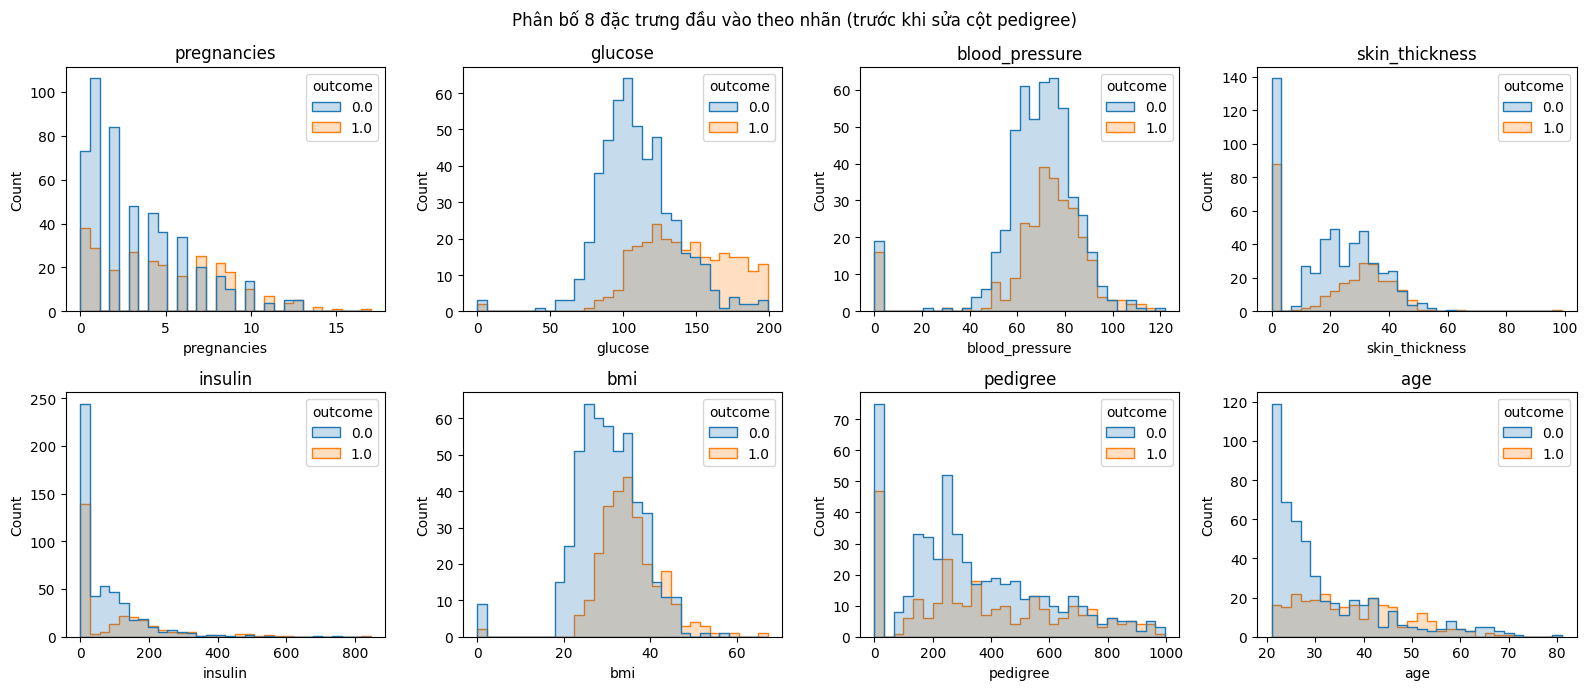

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), short_names[:8]):
    sns.histplot(data=df, x=col, hue="outcome", bins=30, ax=ax, element="step")
    ax.set_title(col)
plt.suptitle("Phân bố 8 đặc trưng đầu vào theo nhãn (trước khi sửa cột pedigree)")
plt.tight_layout()
plt.show()

### **7.1.2 Sửa dữ liệu pedigree**

Một số giá trị bị mất phần `0.`. Các giá trị lớn hơn `2.5` được chia cho `1000` để khôi phục thang đo.

In [35]:
PEDIGREE_COL = 6  # chỉ số cột pedigree trong mảng (0-based), đúng theo thứ tự biến trong sách

pedigree_before = dataset[:, PEDIGREE_COL].copy()
broken_mask = pedigree_before > 2.5
print(f"Số giá trị pedigree bị mất dấu thập phân: {broken_mask.sum()} / {len(dataset)}")
print("Ví dụ trước khi sửa:", pedigree_before[:8])

dataset[broken_mask, PEDIGREE_COL] = dataset[broken_mask, PEDIGREE_COL] / 1000.0

print("Ví dụ sau khi sửa: ", dataset[:8, PEDIGREE_COL])
print(f"Khoảng giá trị sau khi sửa: [{dataset[:, PEDIGREE_COL].min():.3f}, {dataset[:, PEDIGREE_COL].max():.3f}]")

print("\n5 dòng đầu (so với Output 7.1 trong sách):")
for row in dataset[:5]:
    print(",".join(f"{v:g}" for v in row))

df = pd.DataFrame(dataset, columns=short_names)

Số giá trị pedigree bị mất dấu thập phân: 646 / 768
Ví dụ trước khi sửa: [627.    351.    672.    167.      2.288 201.    248.    134.   ]
Ví dụ sau khi sửa:  [0.627 0.351 0.672 0.167 2.288 0.201 0.248 0.134]
Khoảng giá trị sau khi sửa: [0.078, 2.420]

5 dòng đầu (so với Output 7.1 trong sách):
6,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
8,183,64,0,0,23.3,0.672,32,1
1,89,66,23,94,28.1,0.167,21,0
0,137,40,35,168,43.1,2.288,33,1


### **7.1.3 Tách đặc trưng và nhãn**

Tám cột đầu là `X`, cột cuối là `y`. Nhãn đã ở dạng `0`/`1`, không cần mã hóa thêm.

In [36]:
X = dataset[:, 0:8]
y = dataset[:, 8]

print("Các giá trị nhãn duy nhất:", np.unique(y))
print("X shape:", X.shape, "| y shape:", y.shape)

Các giá trị nhãn duy nhất: [0. 1.]
X shape: (768, 8) | y shape: (768,)


### **7.1.4 Chuyển sang tensor**

Dùng `float32`; đổi `y` thành dạng `(n, 1)` để khớp đầu ra của mô hình.

In [37]:
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)

X: torch.Size([768, 8]) torch.float32
y: torch.Size([768, 1]) torch.float32


---

## **7.2 Định nghĩa mô hình**

MLP gồm các lớp `8 → 12 → 8 → 1`, dùng ReLU ở lớp ẩn và Sigmoid ở đầu ra.

### **Cách 1: `nn.Sequential`**

In [38]:
model = nn.Sequential(
    nn.Linear(8, 12),   # lớp ẩn 1: 12 nơ-ron — đủ lớn để học cấu trúc dữ liệu nhưng vẫn nhanh
    nn.ReLU(),          # ReLU tránh vanishing gradient so với sigmoid/tanh
    nn.Linear(12, 8),   # lớp ẩn 2: 8 nơ-ron
    nn.ReLU(),
    nn.Linear(8, 1),    # lớp ra: 1 nơ-ron vì chỉ cần một xác suất cho bài toán nhị phân
    nn.Sigmoid()        # ép đầu ra về (0, 1) để diễn giải như xác suất lớp 1
)
print(model)

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


### **Cách 2: Kế thừa `nn.Module`**

Cách này cho phép định nghĩa mô hình bằng các lớp và phương thức riêng.

In [39]:
class PimaClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(8, 12)
        self.act1 = nn.ReLU()
        self.hidden2 = nn.Linear(12, 8)
        self.act2 = nn.ReLU()
        self.output = nn.Linear(8, 1)
        self.act_output = nn.Sigmoid()

    def forward(self, x):
        x = self.act1(self.hidden1(x))
        x = self.act2(self.hidden2(x))
        x = self.act_output(self.output(x))
        return x


model = PimaClassifier()
print(model)

PimaClassifier(
  (hidden1): Linear(in_features=8, out_features=12, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=12, out_features=8, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
  (act_output): Sigmoid()
)


---

## **7.3 Hàm mất mát và bộ tối ưu**

Dùng `BCELoss` cho phân loại nhị phân và `Adam` với `lr=0.001`.

In [40]:
loss_fn = nn.BCELoss()  # binary cross-entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(loss_fn)
print(optimizer)

BCELoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


---

## **7.4 Huấn luyện mô hình**

Huấn luyện 100 epoch, batch size 10. Mỗi batch thực hiện lan truyền thuận, tính loss, lan truyền ngược và cập nhật trọng số.

In [41]:
n_epochs = 100   # số lần duyệt toàn bộ dữ liệu, theo sách
batch_size = 10  # batch nhỏ -> nhiều lần cập nhật trọng số mỗi epoch, đánh đổi giữa tốc độ và độ ổn định

ch7_epoch_losses = []  # lưu loss trung bình mỗi epoch để vẽ đường cong hội tụ

for epoch in range(n_epochs):
    batch_losses = []
    for i in range(0, len(X), batch_size):
        Xbatch = X[i:i + batch_size]
        y_pred = model(Xbatch)            # lan truyền thuận: tính xác suất dự đoán
        ybatch = y[i:i + batch_size]
        loss = loss_fn(y_pred, ybatch)    # đo sai lệch so với nhãn thật
        optimizer.zero_grad()             # xóa gradient cũ vì PyTorch cộng dồn gradient theo mặc định
        loss.backward()                   # lan truyền ngược: tính gradient cho mọi tham số
        optimizer.step()                  # cập nhật trọng số theo gradient vừa tính
        batch_losses.append(loss.item())
    ch7_epoch_losses.append(np.mean(batch_losses))
    print(f"Finished epoch {epoch}, latest loss {loss}")

Finished epoch 0, latest loss 0.6087607741355896
Finished epoch 1, latest loss 0.5802512764930725
Finished epoch 2, latest loss 0.5543873310089111
Finished epoch 3, latest loss 0.5136255025863647
Finished epoch 4, latest loss 0.4809136390686035
Finished epoch 5, latest loss 0.4603784382343292
Finished epoch 6, latest loss 0.44923949241638184
Finished epoch 7, latest loss 0.4404149353504181
Finished epoch 8, latest loss 0.4340861141681671
Finished epoch 9, latest loss 0.4314538836479187
Finished epoch 10, latest loss 0.4298568367958069
Finished epoch 11, latest loss 0.43249526619911194
Finished epoch 12, latest loss 0.4369887113571167
Finished epoch 13, latest loss 0.4377707839012146
Finished epoch 14, latest loss 0.44010013341903687
Finished epoch 15, latest loss 0.4437657594680786
Finished epoch 16, latest loss 0.44391560554504395
Finished epoch 17, latest loss 0.46600857377052307
Finished epoch 18, latest loss 0.4647836983203888
Finished epoch 19, latest loss 0.47820255160331726
Fini

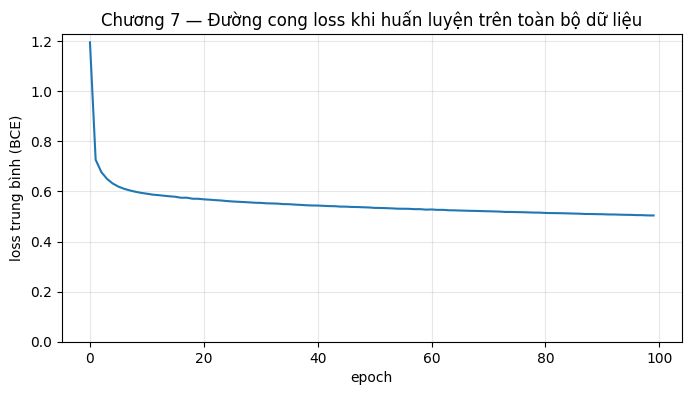

In [42]:
plt.figure(figsize=(8, 4))
plt.plot(ch7_epoch_losses)
plt.xlabel("epoch")
plt.ylabel("loss trung bình (BCE)")
plt.title("Chương 7 — Đường cong loss khi huấn luyện trên toàn bộ dữ liệu")
plt.ylim(0)
plt.grid(alpha=0.3)
plt.show()

---

## **7.5 Đánh giá mô hình**

Đánh giá trên dữ liệu huấn luyện để theo dõi mức độ mô hình khớp dữ liệu. Chương 8 sẽ đánh giá thêm trên tập test.

In [43]:
with torch.no_grad():
    y_pred = model(X)
accuracy = (y_pred.round() == y).float().mean()
print(f"Accuracy {accuracy}")

Accuracy 0.7643229365348816


### **Ảnh hưởng của khởi tạo ngẫu nhiên**

Khởi tạo trọng số khác nhau có thể làm accuracy thay đổi. Chạy nhiều lần và lấy trung bình giúp đánh giá ổn định hơn.

In [44]:
def train_and_evaluate_full(X, y, n_epochs=100, batch_size=10, lr=0.001):
    run_model = nn.Sequential(
        nn.Linear(8, 12), nn.ReLU(),
        nn.Linear(12, 8), nn.ReLU(),
        nn.Linear(8, 1), nn.Sigmoid()
    )
    run_loss_fn = nn.BCELoss()
    run_optimizer = optim.Adam(run_model.parameters(), lr=lr)
    for epoch in range(n_epochs):
        for i in range(0, len(X), batch_size):
            Xbatch = X[i:i + batch_size]
            ybatch = y[i:i + batch_size]
            loss = run_loss_fn(run_model(Xbatch), ybatch)
            run_optimizer.zero_grad()
            loss.backward()
            run_optimizer.step()
    with torch.no_grad():
        return (run_model(X).round() == y).float().mean().item()


repeat_accuracies = []
for run in range(5):
    acc = train_and_evaluate_full(X, y)
    repeat_accuracies.append(acc)
    print(f"Run {run + 1} - Accuracy: {acc}")

print(f"\nAccuracy trung bình: {np.mean(repeat_accuracies):.4f} ± {np.std(repeat_accuracies):.4f}")

Run 1 - Accuracy: 0.76171875
Run 2 - Accuracy: 0.7591145634651184
Run 3 - Accuracy: 0.7669270634651184
Run 4 - Accuracy: 0.76953125
Run 5 - Accuracy: 0.7747395634651184

Accuracy trung bình: 0.7664 ± 0.0056


---

## **7.6 Dự đoán**

Sigmoid trả về xác suất. Chuyển xác suất thành nhãn bằng `round()` hoặc ngưỡng `0.5`, rồi đối chiếu một số mẫu với nhãn thật.

In [45]:
with torch.no_grad():
    predictions = model(X)
    rounded = predictions.round()

    class_predictions = (model(X) > 0.5).int()

print("Hai cách đổi xác suất -> nhãn có khớp nhau:", bool((rounded.int() == class_predictions).all()))

for i in range(5):
    print("%s => %d (expected %d)" % (X[i].tolist(), class_predictions[i].item(), y[i].item()))

Hai cách đổi xác suất -> nhãn có khớp nhau: True
[6.0, 148.0, 72.0, 35.0, 0.0, 33.599998474121094, 0.6269999742507935, 50.0] => 1 (expected 1)
[1.0, 85.0, 66.0, 29.0, 0.0, 26.600000381469727, 0.35100001096725464, 31.0] => 0 (expected 0)
[8.0, 183.0, 64.0, 0.0, 0.0, 23.299999237060547, 0.671999990940094, 32.0] => 1 (expected 1)
[1.0, 89.0, 66.0, 23.0, 94.0, 28.100000381469727, 0.16699999570846558, 21.0] => 0 (expected 0)
[0.0, 137.0, 40.0, 35.0, 168.0, 43.099998474121094, 2.2880001068115234, 33.0] => 1 (expected 1)


---
# **Chương 8: Vòng lặp huấn luyện**

## **8.1 Tách tập huấn luyện và kiểm tra**

Dùng 700 mẫu để huấn luyện và 68 mẫu để kiểm tra khả năng tổng quát hóa.

### **8.1.1. Chia dữ liệu**

In [46]:
Xtrain = X[:700]
ytrain = y[:700]
Xtest = X[700:]
ytest = y[700:]

print("Train:", Xtrain.shape, ytrain.shape)
print("Test: ", Xtest.shape, ytest.shape)
print(f"Tỉ lệ lớp 1 — train: {ytrain.mean():.3f} | test: {ytest.mean():.3f}")

Train: torch.Size([700, 8]) torch.Size([700, 1])
Test:  torch.Size([68, 8]) torch.Size([68, 1])
Tỉ lệ lớp 1 — train: 0.344 | test: 0.397


### **8.1.2. Mô hình và vòng lặp tối thiểu**

Tạo mô hình mới, huấn luyện 50 epoch với batch size 10; chỉ dùng tập train để cập nhật trọng số.

In [47]:
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(8, 12),
    nn.ReLU(),
    nn.Linear(12, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid()
)
print(model)

loss_fn = nn.BCELoss()  # binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


In [48]:
n_epochs = 50    # number of epochs to run
batch_size = 10  # size of each batch
batches_per_epoch = len(Xtrain) // batch_size

for epoch in range(n_epochs):
    for i in range(batches_per_epoch):
        start = i * batch_size
        Xbatch = Xtrain[start:start + batch_size]
        ybatch = ytrain[start:start + batch_size]
        y_pred = model(Xbatch)
        loss = loss_fn(y_pred, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

print(f"Hoàn tất {n_epochs} epoch, loss batch cuối: {loss.item():.4f}")

Hoàn tất 50 epoch, loss batch cuối: 0.6314


### **8.1.3. Đánh giá sau huấn luyện**

So sánh accuracy trên toàn bộ dữ liệu và trên tập test; kết quả test là thước đo chính.

In [49]:
with torch.no_grad():
    y_pred_all = model(X)
    accuracy_all = (y_pred_all.round() == y).float().mean()
    y_pred_test = model(Xtest)
    accuracy_test = (y_pred_test.round() == ytest).float().mean()

print("Accuracy (toàn bộ X, như mã Listing 8.4) {:.2f}".format(accuracy_all * 100))
print("Accuracy (tập test)                      {:.2f}".format(accuracy_test * 100))

Accuracy (toàn bộ X, như mã Listing 8.4) 74.61
Accuracy (tập test)                      67.65


---

## **8.2 Theo dõi quá trình huấn luyện**

Ghi nhận loss theo batch, accuracy train và accuracy test theo epoch để theo dõi quá trình học. Dùng `lr=0.0001`.

In [50]:
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(8, 12),
    nn.ReLU(),
    nn.Linear(12, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid()
)
print(model)

loss_fn = nn.BCELoss()  # binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.0001)

n_epochs = 50    # number of epochs to run
batch_size = 10  # size of each batch
batches_per_epoch = len(Xtrain) // batch_size

train_loss = []
train_acc = []
test_acc = []

for epoch in range(n_epochs):
    for i in range(batches_per_epoch):
        start = i * batch_size
        Xbatch = Xtrain[start:start + batch_size]
        ybatch = ytrain[start:start + batch_size]
        y_pred = model(Xbatch)
        loss = loss_fn(y_pred, ybatch)
        acc = (y_pred.round() == ybatch).float().mean()
        train_loss.append(float(loss))
        train_acc.append(float(acc))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        print(f"epoch {epoch} step {i} loss {loss} accuracy {acc}")
    with torch.no_grad():
        y_pred = model(Xtest)
    acc = (y_pred.round() == ytest).float().mean()
    test_acc.append(float(acc))
    print(f"End of {epoch}, accuracy {acc}")

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)
epoch 0 step 0 loss 0.7952821850776672 accuracy 0.4000000059604645
epoch 0 step 1 loss 1.032567024230957 accuracy 0.4000000059604645
epoch 0 step 2 loss 0.6410035490989685 accuracy 0.800000011920929
epoch 0 step 3 loss 0.6048004627227783 accuracy 0.6000000238418579
epoch 0 step 4 loss 0.6155502200126648 accuracy 0.699999988079071
epoch 0 step 5 loss 0.6437240242958069 accuracy 0.699999988079071
epoch 0 step 6 loss 0.6842021346092224 accuracy 0.5
epoch 0 step 7 loss 0.698219895362854 accuracy 0.30000001192092896
epoch 0 step 8 loss 0.72797691822052 accuracy 0.6000000238418579
epoch 0 step 9 loss 0.6899510622024536 accuracy 0.6000000238418579
epoch 0 step 10 loss 0.6523457765579224 accuracy 0.5
epoch 0 step 11 loss 0.8136807680130005 accuracy 0.699999988079071
ep

### **Trực quan hóa**

Vẽ loss và accuracy theo thời gian. Accuracy train được lấy trung bình theo từng epoch để so sánh với accuracy test.

Notebook dùng `batches_per_epoch` để tính đúng phạm vi trung bình.

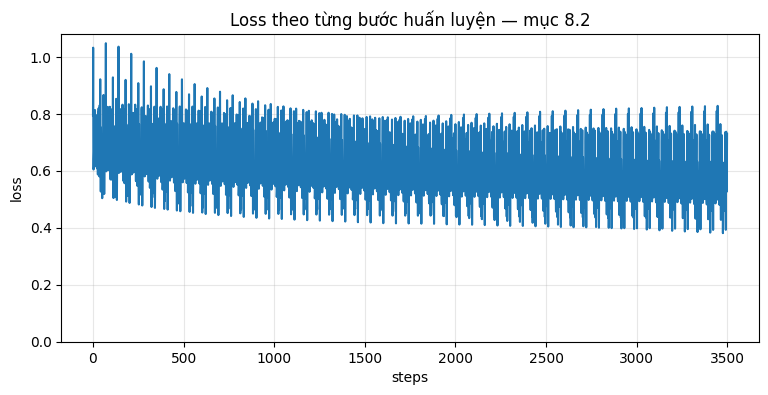

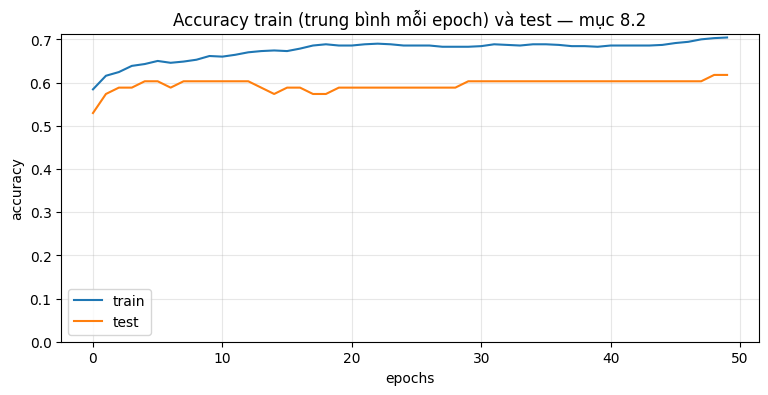

Accuracy train trung bình epoch cuối: 0.7043
Accuracy test epoch cuối:             0.6176


In [51]:
def plot_training_curves(train_loss, train_acc, test_acc, n_epochs, batches_per_epoch, title_suffix=""):
    plt.figure(figsize=(9, 4))
    plt.plot(train_loss)
    plt.xlabel("steps")
    plt.ylabel("loss")
    plt.ylim(0)
    plt.title(f"Loss theo từng bước huấn luyện{title_suffix}")
    plt.grid(alpha=0.3)
    plt.show()

    avg_train_acc = []
    for i in range(n_epochs):
        start = i * batches_per_epoch
        average = sum(train_acc[start:start + batches_per_epoch]) / batches_per_epoch
        avg_train_acc.append(average)

    plt.figure(figsize=(9, 4))
    plt.plot(avg_train_acc, label="train")
    plt.plot(test_acc, label="test")
    plt.xlabel("epochs")
    plt.ylabel("accuracy")
    plt.ylim(0)
    plt.legend()
    plt.title(f"Accuracy train (trung bình mỗi epoch) và test{title_suffix}")
    plt.grid(alpha=0.3)
    plt.show()
    return avg_train_acc


avg_train_acc_82 = plot_training_curves(train_loss, train_acc, test_acc, n_epochs, batches_per_epoch, " — mục 8.2")
print(f"Accuracy train trung bình epoch cuối: {avg_train_acc_82[-1]:.4f}")
print(f"Accuracy test epoch cuối:             {test_acc[-1]:.4f}")
ch82_final_test_acc = test_acc[-1]

Checkpointing và early stopping không nằm trong phạm vi notebook này.

---

## **8.3 Hiển thị tiến trình bằng `tqdm`**

Dùng thanh tiến trình để theo dõi huấn luyện mà không in quá nhiều dòng.

### **Cách 1: `tqdm.trange()`**

`trange()` kết hợp `range()` với thanh tiến trình.

In [52]:
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(8, 12),
    nn.ReLU(),
    nn.Linear(12, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid()
)
print(model)

loss_fn = nn.BCELoss()  # binary cross entropy
optimizer = optim.Adam(model.parameters(), lr=0.0001)

n_epochs = 50    # number of epochs to run
batch_size = 10  # size of each batch
batches_per_epoch = len(Xtrain) // batch_size

train_loss = []
train_acc = []
test_acc = []

for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
            start = i * batch_size
            Xbatch = Xtrain[start:start + batch_size]
            ybatch = ytrain[start:start + batch_size]
            y_pred = model(Xbatch)
            loss = loss_fn(y_pred, ybatch)
            acc = (y_pred.round() == ybatch).float().mean()
            train_loss.append(float(loss))
            train_acc.append(float(acc))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            bar.set_postfix(
                loss=float(loss),
                acc=f"{float(acc) * 100:.2f}%"
            )
    with torch.no_grad():
        y_pred = model(Xtest)
    acc = (y_pred.round() == ytest).float().mean()
    test_acc.append(float(acc))
    print(f"End of {epoch}, accuracy {acc}")

Sequential(
  (0): Linear(in_features=8, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


Epoch 0:   0%|          | 0/70 [00:00<?, ?batch/s]

Epoch 0: 100%|██████████| 70/70 [00:00<00:00, 267.72batch/s, acc=60.00%, loss=0.811]


End of 0, accuracy 0.529411792755127


Epoch 1: 100%|██████████| 70/70 [00:00<00:00, 303.48batch/s, acc=70.00%, loss=0.805]


...

End of 47, accuracy 0.6029411554336548


Epoch 48: 100%|██████████| 70/70 [00:00<00:00, 307.98batch/s, acc=50.00%, loss=0.73]  


End of 48, accuracy 0.6176470518112183


Epoch 49: 100%|██████████| 70/70 [00:00<00:00, 304.92batch/s, acc=50.00%, loss=0.73]  


End of 49, accuracy 0.6176470518112183


### **Cách 2: `tqdm.tqdm()`**

Duyệt danh sách vị trí bắt đầu của các batch bằng `tqdm()` và lưu thống kê để đánh giá.

In [53]:
torch.manual_seed(SEED)
final_model = nn.Sequential(
    nn.Linear(8, 12),
    nn.ReLU(),
    nn.Linear(12, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid()
)
loss_fn = nn.BCELoss()  # binary cross entropy
optimizer = optim.Adam(final_model.parameters(), lr=0.0001)

n_epochs = 50
batch_size = 10
batches_per_epoch = len(Xtrain) // batch_size

final_train_loss = []
final_train_acc = []
final_test_acc = []
final_test_loss = []  # bổ sung: loss trên tập test mỗi epoch để vẽ đường cong loss train vs test

starts = [i * batch_size for i in range(batches_per_epoch)]

for epoch in range(n_epochs):
    with tqdm.tqdm(starts, unit="batch", mininterval=0) as bar:
        bar.set_description(f"Epoch {epoch}")
        for start in bar:
            Xbatch = Xtrain[start:start + batch_size]
            ybatch = ytrain[start:start + batch_size]
            y_pred = final_model(Xbatch)
            loss = loss_fn(y_pred, ybatch)
            acc = (y_pred.round() == ybatch).float().mean()
            final_train_loss.append(float(loss))
            final_train_acc.append(float(acc))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            bar.set_postfix(
                loss=float(loss),
                acc=f"{float(acc) * 100:.2f}%"
            )
    with torch.no_grad():
        y_pred = final_model(Xtest)
        final_test_loss.append(float(loss_fn(y_pred, ytest)))
    acc = (y_pred.round() == ytest).float().mean()
    final_test_acc.append(float(acc))
    print(f"End of {epoch}, accuracy {acc}")

Epoch 0: 100%|██████████| 70/70 [00:00<00:00, 305.69batch/s, acc=60.00%, loss=0.811]


End of 0, accuracy 0.529411792755127


Epoch 1: 100%|██████████| 70/70 [00:00<00:00, 308.39batch/s, acc=70.00%, loss=0.805]


End of 1, accuracy 0.5735294222831726


Epoch 2: 100%|██████████| 70/70 [00:00<00:00, 312.60batch/s, acc=70.00%, loss=0.794] 


...

End of 47, accuracy 0.6029411554336548


Epoch 48: 100%|██████████| 70/70 [00:00<00:00, 320.54batch/s, acc=50.00%, loss=0.73]  


End of 48, accuracy 0.6176470518112183


Epoch 49: 100%|██████████| 70/70 [00:00<00:00, 318.57batch/s, acc=50.00%, loss=0.73]  


End of 49, accuracy 0.6176470518112183


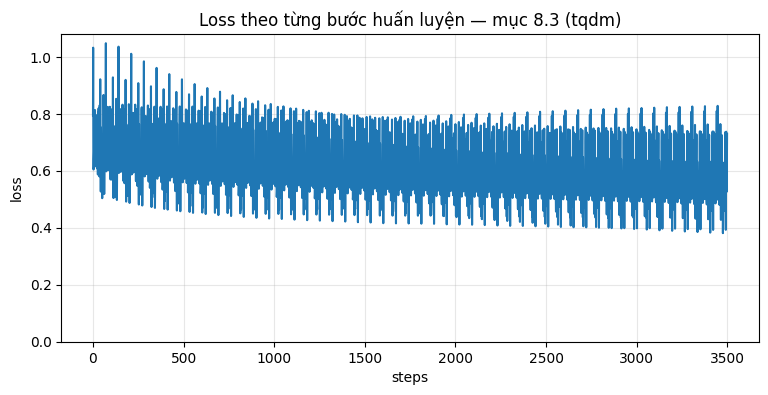

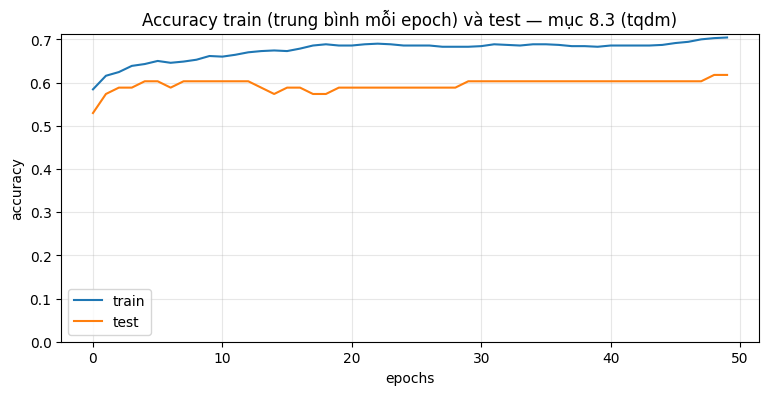

In [54]:
avg_train_acc_final = plot_training_curves(
    final_train_loss, final_train_acc, final_test_acc, n_epochs, batches_per_epoch, " — mục 8.3 (tqdm)"
)

---
## **9. Đánh giá tổng hợp**

Tổng hợp accuracy, loss train/test và ma trận nhầm lẫn của mô hình cuối trên tập test.

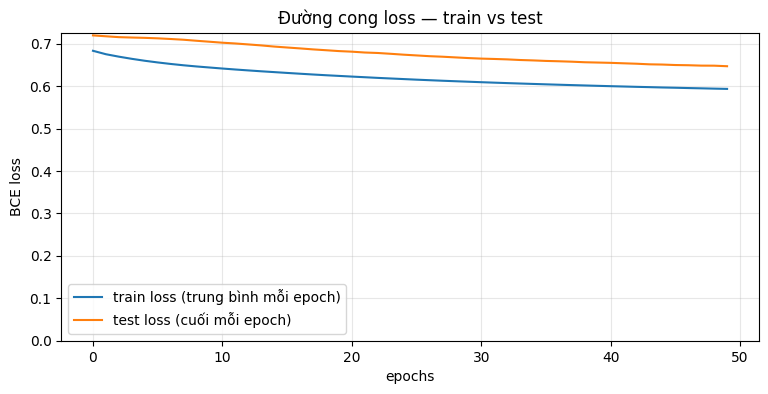

In [55]:
epoch_train_loss = [np.mean(final_train_loss[e * batches_per_epoch:(e + 1) * batches_per_epoch])
                    for e in range(n_epochs)]

plt.figure(figsize=(9, 4))
plt.plot(epoch_train_loss, label="train loss (trung bình mỗi epoch)")
plt.plot(final_test_loss, label="test loss (cuối mỗi epoch)")
plt.xlabel("epochs")
plt.ylabel("BCE loss")
plt.ylim(0)
plt.legend()
plt.title("Đường cong loss — train vs test")
plt.grid(alpha=0.3)
plt.show()

In [56]:
with torch.no_grad():
    train_prob = final_model(Xtrain)
    test_prob = final_model(Xtest)

train_pred = (train_prob > 0.5).int().numpy().ravel()
test_pred = (test_prob > 0.5).int().numpy().ravel()
train_true = ytrain.int().numpy().ravel()
test_true = ytest.int().numpy().ravel()

train_accuracy = (train_pred == train_true).mean()
test_accuracy = (test_pred == test_true).mean()
baseline_accuracy = max(test_true.mean(), 1 - test_true.mean())

print(f"Accuracy tập train : {train_accuracy:.4f}")
print(f"Accuracy tập test  : {test_accuracy:.4f}")
print(f"Baseline (luôn đoán lớp chiếm đa số trên test): {baseline_accuracy:.4f}")

print("\nClassification report (tập test):")
print(classification_report(test_true, test_pred, target_names=["Không tiểu đường (0)", "Tiểu đường (1)"], digits=4))

Accuracy tập train : 0.6957
Accuracy tập test  : 0.6176
Baseline (luôn đoán lớp chiếm đa số trên test): 0.6029

Classification report (tập test):
                      precision    recall  f1-score   support

Không tiểu đường (0)     0.6271    0.9024    0.7400        41
      Tiểu đường (1)     0.5556    0.1852    0.2778        27

            accuracy                         0.6176        68
           macro avg     0.5913    0.5438    0.5089        68
        weighted avg     0.5987    0.6176    0.5565        68



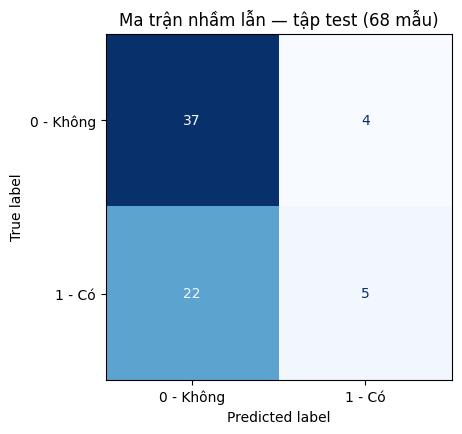

TN=37, FP=4, FN=22, TP=5


In [57]:
cm = confusion_matrix(test_true, test_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["0 - Không", "1 - Có"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Ma trận nhầm lẫn — tập test (68 mẫu)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

In [58]:
summary = pd.DataFrame([
    ["Ch.7 — train & đánh giá trên toàn bộ dữ liệu (lr=0.001, 100 epoch)", float(accuracy)],
    ["Ch.7 — trung bình 5 lần chạy lại", float(np.mean(repeat_accuracies))],
    ["Ch.8.1 — đánh giá trên tập test (lr=0.001, 50 epoch)", float(accuracy_test)],
    ["Ch.8.2 — accuracy test epoch cuối (lr=0.0001)", float(ch82_final_test_acc)],
    ["Ch.8.3 — mô hình cuối, accuracy train", float(train_accuracy)],
    ["Ch.8.3 — mô hình cuối, accuracy test", float(test_accuracy)],
], columns=["Thí nghiệm", "Accuracy"])
display(summary.style.format({"Accuracy": "{:.4f}"}))

,Thí nghiệm,Accuracy
0,"Ch.7 — train & đánh giá trên toàn bộ dữ liệu (lr=0.001, 100 epoch)",0.7643
1,Ch.7 — trung bình 5 lần chạy lại,0.7664
2,"Ch.8.1 — đánh giá trên tập test (lr=0.001, 50 epoch)",0.6765
3,Ch.8.2 — accuracy test epoch cuối (lr=0.0001),0.6176
4,"Ch.8.3 — mô hình cuối, accuracy train",0.6957
5,"Ch.8.3 — mô hình cuối, accuracy test",0.6176


---
## **Tóm tắt**

Notebook đã xây dựng và huấn luyện MLP phân loại nhị phân trên dữ liệu Pima. Chương 7 minh họa mô hình, loss, optimizer, dự đoán và đánh giá; Chương 8 bổ sung tập test, thống kê huấn luyện và thanh tiến trình.

Accuracy cần được xem cùng loss và ma trận nhầm lẫn; tập test nhỏ nên kết quả có thể dao động.

# <center>**HẾT**<center>